# Part 3: Sound Data Collection and Processing

This notebook loads the team voice samples, inspects original waveforms and spectrograms, applies two deterministic augmentations to each recording, and extracts summary audio features for downstream multimodal experiments.

The repository currently contains six recordings: two phrases each from Bridget, Merci, and Yves.

## 1. Import Required Libraries

In [1]:
from pathlib import Path
import sys
import zlib

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import display

working_dir = Path.cwd().resolve()
project_candidates = [working_dir, working_dir / "repository", *working_dir.parents]
PROJECT_ROOT = next(
    path for path in project_candidates if (path / "scripts" / "process_audio.py").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from process_audio import HOP_LENGTH, N_FFT, extract_features, make_noise_augmentation

AUDIO_DIR = PROJECT_ROOT / "data" / "raw" / "audio"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOT_DIR = PROJECT_ROOT / "reports" / "audio_visualizations"
print(f"Project root: {PROJECT_ROOT}")
print(f"Audio input folder: {AUDIO_DIR}")

Project root: /Users/nives/ALU/ML_pipeline/repository
Audio input folder: /Users/nives/ALU/ML_pipeline/repository/data/raw/audio


## 2. Load and Preview Audio Samples

Files use the `Member_phrase.mp3` naming convention. The filename supplies the speaker and phrase labels; each file is decoded to mono without changing its original sample rate.

In [2]:
audio_paths = sorted(path for path in AUDIO_DIR.glob("*") if path.suffix.lower() in {".mp3", ".wav"})
if not audio_paths:
    raise FileNotFoundError(f"No MP3 or WAV recordings found in {AUDIO_DIR}")

recordings = {}
preview_rows = []
for audio_path in audio_paths:
    speaker, phrase = audio_path.stem.split("_", maxsplit=1)
    waveform, sample_rate = librosa.load(audio_path, sr=None, mono=True)
    recordings[audio_path.stem] = {
        "speaker": speaker,
        "phrase": phrase,
        "waveform": waveform.astype(np.float32),
        "sample_rate": sample_rate,
        "source_path": audio_path,
    }
    preview_rows.append(
        {
            "speaker": speaker,
            "phrase": phrase,
            "file": audio_path.name,
            "sample_rate_hz": sample_rate,
            "duration_seconds": len(waveform) / sample_rate,
        }
    )

preview = pd.DataFrame(preview_rows)
display(preview)
print(f"Loaded {len(recordings)} recordings from {preview['speaker'].nunique()} speakers.")

,speaker,phrase,file,sample_rate_hz,duration_seconds
0,Bridget,approve,Bridget_approve.mp3,48000,2.816000
1,Bridget,transaction,Bridget_transaction.mp3,48000,2.986667
2,Merci,approve,Merci_approve.mp3,48000,2.304000
3,Merci,transaction,Merci_transaction.mp3,48000,3.328000
4,Yves,approve,Yves_approve.mp3,48000,2.665125
5,Yves,transaction,Yves_transaction.mp3,48000,2.466958


Loaded 6 recordings from 3 speakers.


## 3. Visualize Audio: Waveforms and Spectrograms

Each member's original recordings are shown as time-domain waveforms and short-time Fourier transform spectrograms. These plots help check clip duration, pauses, clipping, and the distribution of speech energy across frequency.

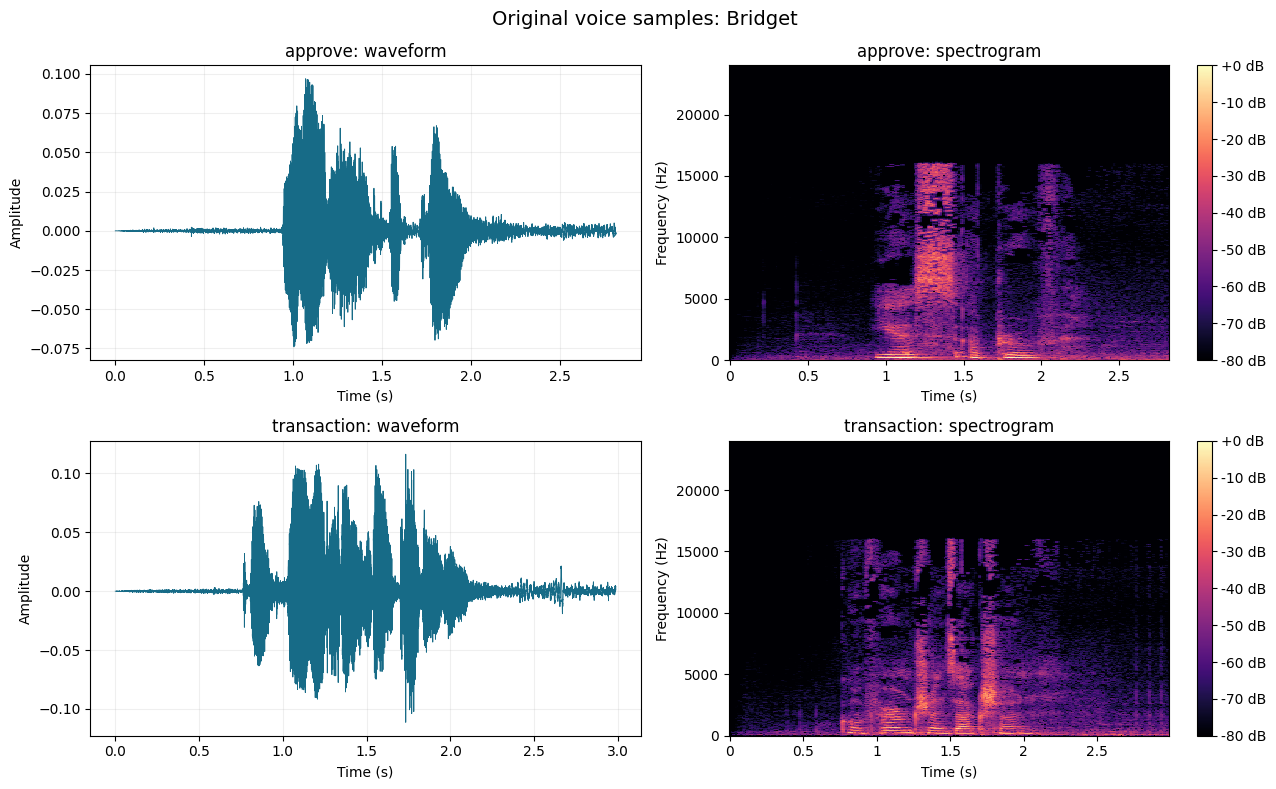

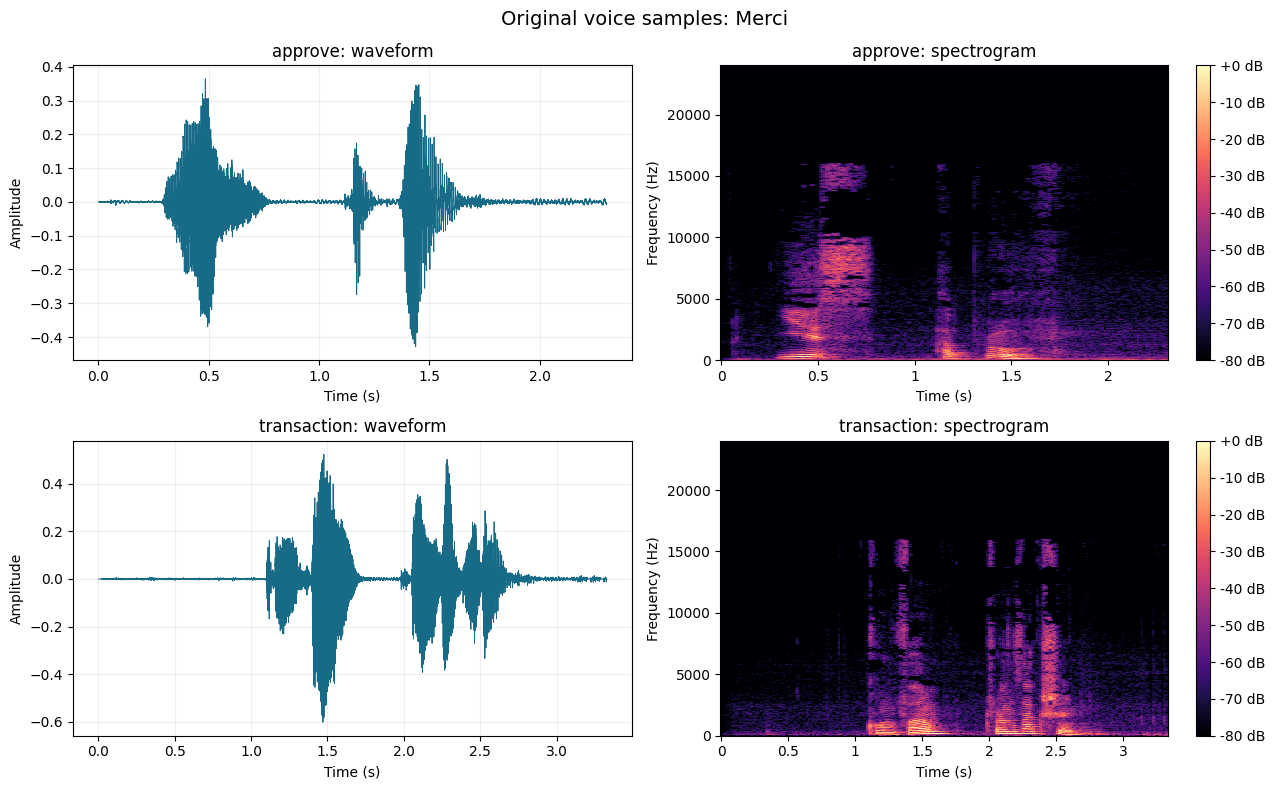

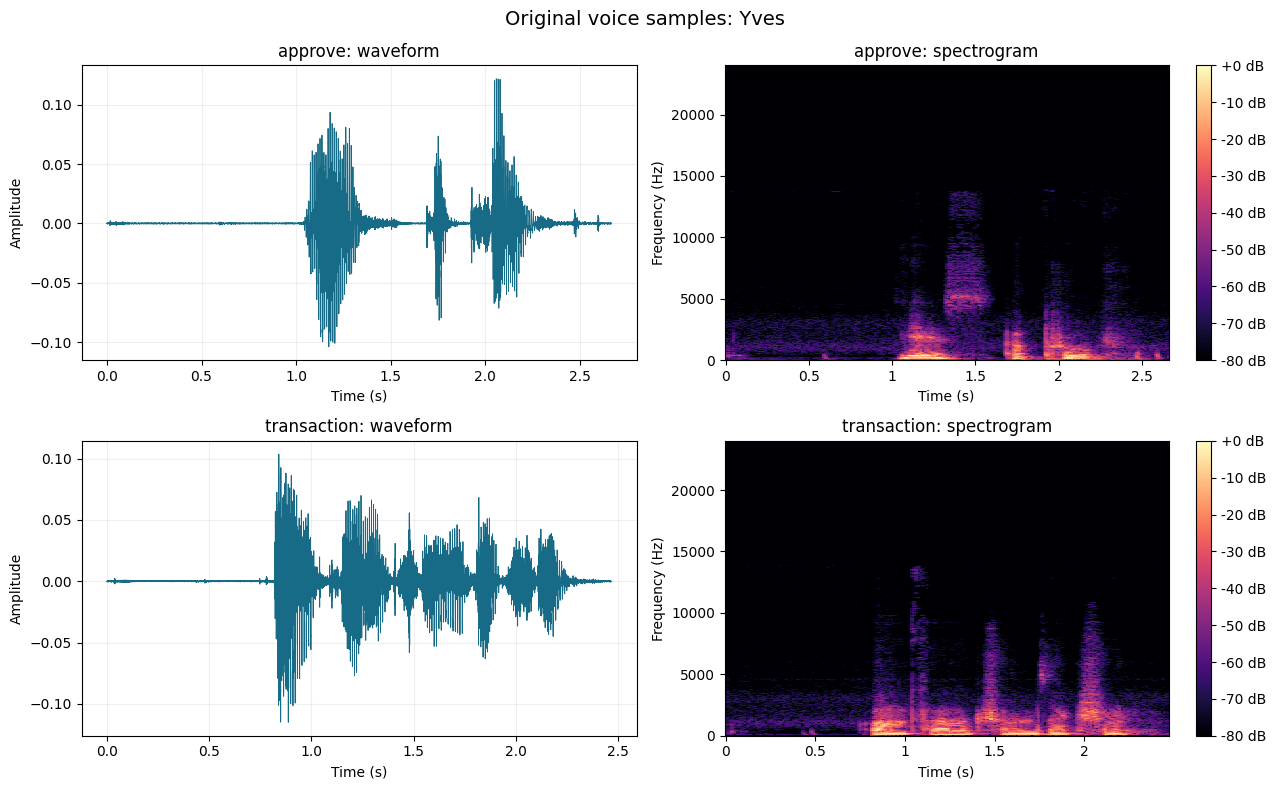

In [3]:
for speaker in sorted({recording["speaker"] for recording in recordings.values()}):
    speaker_items = sorted(
        (recording for recording in recordings.values() if recording["speaker"] == speaker),
        key=lambda item: item["phrase"],
    )
    figure, axes = plt.subplots(len(speaker_items), 2, figsize=(13, 4 * len(speaker_items)))
    axes = np.atleast_2d(axes)

    for row, recording in enumerate(speaker_items):
        waveform = recording["waveform"]
        sample_rate = recording["sample_rate"]
        phrase = recording["phrase"]
        time_axis = np.arange(len(waveform)) / sample_rate
        axes[row, 0].plot(time_axis, waveform, linewidth=0.65, color="#176b87")
        axes[row, 0].set(title=f"{phrase}: waveform", xlabel="Time (s)", ylabel="Amplitude")
        axes[row, 0].grid(alpha=0.2)

        stft = librosa.stft(waveform, n_fft=N_FFT, hop_length=HOP_LENGTH)
        decibels = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
        image = librosa.display.specshow(
            decibels,
            sr=sample_rate,
            hop_length=HOP_LENGTH,
            x_axis="time",
            y_axis="hz",
            cmap="magma",
            ax=axes[row, 1],
        )
        axes[row, 1].set(title=f"{phrase}: spectrogram", xlabel="Time (s)", ylabel="Frequency (Hz)")
        figure.colorbar(image, ax=axes[row, 1], format="%+2.0f dB")

    figure.suptitle(f"Original voice samples: {speaker}", fontsize=14)
    figure.tight_layout()
    plot_path = PLOT_DIR / f"{speaker.lower()}_waveforms_spectrograms.png"
    plot_path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(plot_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)

## 4. Audio Data Augmentation

For each original clip, create two additional versions: a pitch shift of +2 semitones and deterministic white noise at approximately 30 dB signal-to-noise ratio. These are robustness examples, not new independent speaker recordings. The augmented WAVs are saved under `data/processed/audio_augmentations/` and their waveforms are displayed below.

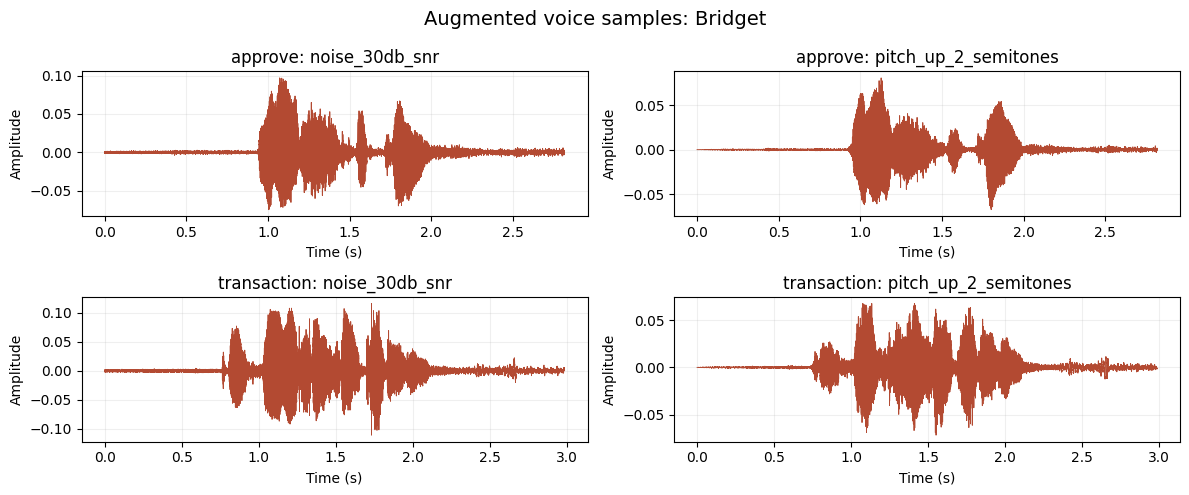

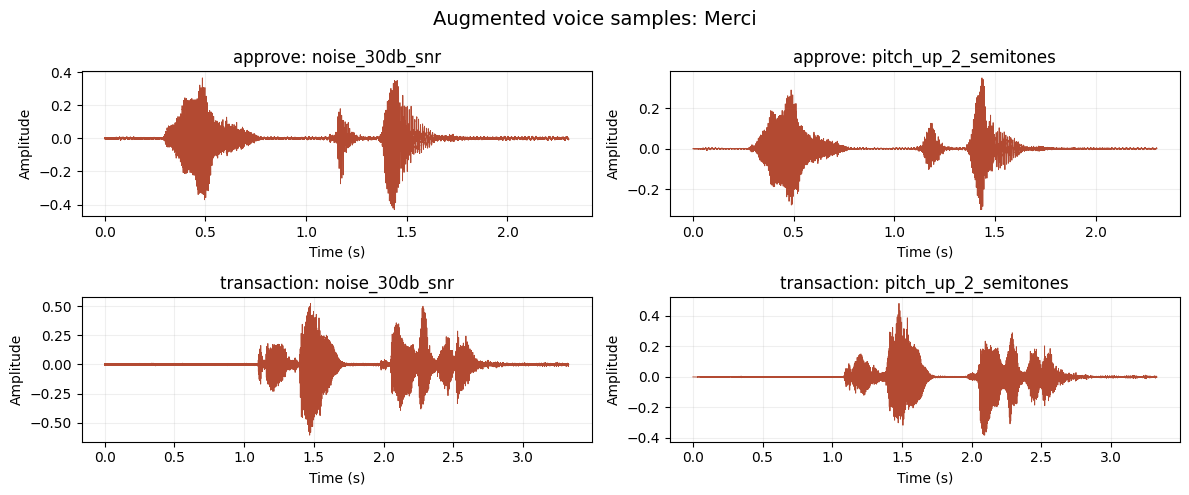

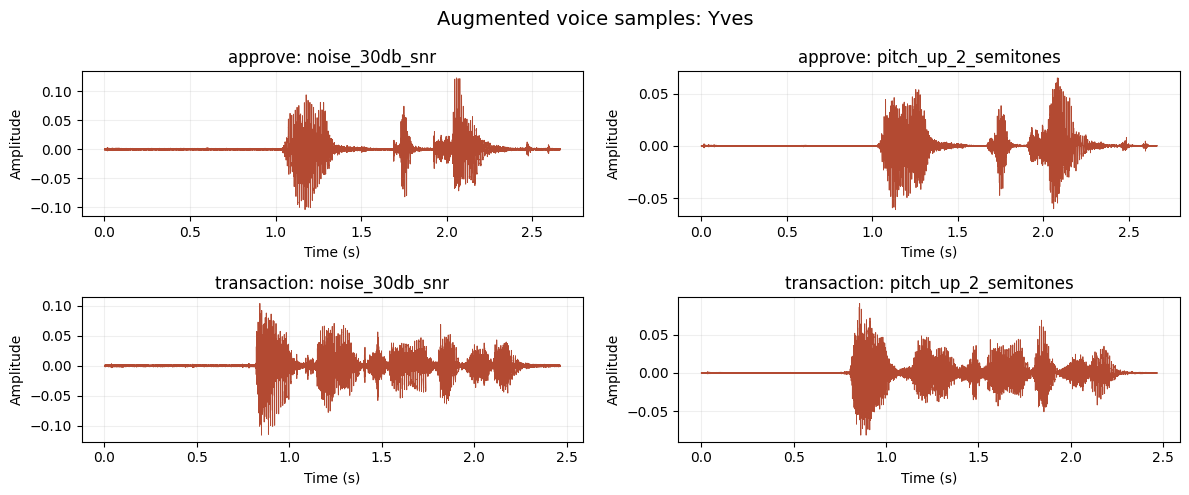

Prepared 18 original and augmented audio examples.


In [4]:
augmented_records = []
augmentation_dir = PROCESSED_DIR / "audio_augmentations"

for sample_id, recording in recordings.items():
    source_path = recording["source_path"]
    speaker = recording["speaker"]
    phrase = recording["phrase"]
    waveform = recording["waveform"]
    sample_rate = recording["sample_rate"]
    seed = zlib.crc32(source_path.name.encode("utf-8"))
    variants = [
        ("original", waveform, None),
        (
            "pitch_up_2_semitones",
            librosa.effects.pitch_shift(waveform, sr=sample_rate, n_steps=2).astype(np.float32),
            "pitch_up_2_semitones",
        ),
        ("noise_30db_snr", make_noise_augmentation(waveform, seed), "noise_30db_snr"),
    ]

    for augmentation, variant, output_suffix in variants:
        if output_suffix is None:
            audio_path = source_path
        else:
            audio_path = augmentation_dir / f"{sample_id}_{output_suffix}.wav"
            audio_path.parent.mkdir(parents=True, exist_ok=True)
            sf.write(audio_path, variant, sample_rate)
        augmented_records.append(
            {
                "sample_id": sample_id,
                "speaker": speaker,
                "phrase": phrase,
                "augmentation": augmentation,
                "waveform": variant,
                "sample_rate": sample_rate,
                "audio_file": audio_path.relative_to(PROJECT_ROOT).as_posix(),
            }
        )

for speaker in sorted({recording["speaker"] for recording in recordings.values()}):
    speaker_augments = [
        recording
        for recording in augmented_records
        if recording["speaker"] == speaker and recording["augmentation"] != "original"
    ]
    figure, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=False)
    for axis, recording in zip(axes.flat, sorted(speaker_augments, key=lambda item: (item["phrase"], item["augmentation"]))):
        time_axis = np.arange(len(recording["waveform"])) / recording["sample_rate"]
        axis.plot(time_axis, recording["waveform"], linewidth=0.65, color="#b34a32")
        axis.set(
            title=f"{recording['phrase']}: {recording['augmentation']}",
            xlabel="Time (s)",
            ylabel="Amplitude",
        )
        axis.grid(alpha=0.2)
    figure.suptitle(f"Augmented voice samples: {speaker}", fontsize=14)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

print(f"Prepared {len(augmented_records)} original and augmented audio examples.")

## 5. Feature Extraction from Audio Samples

Extract 13 MFCC coefficients (mean and standard deviation), spectral roll-off, RMS energy, spectral centroid, and zero-crossing rate from every original and augmented clip. Each CSV row retains the speaker, phrase, augmentation, sample rate, duration, and relative audio path.

In [5]:
feature_rows = []
for recording in augmented_records:
    feature_rows.append(
        {
            "sample_id": f"{recording['sample_id']}__{recording['augmentation']}",
            "speaker": recording["speaker"],
            "phrase": recording["phrase"],
            "augmentation": recording["augmentation"],
            "audio_file": recording["audio_file"],
            "sample_rate_hz": recording["sample_rate"],
            "duration_seconds": len(recording["waveform"]) / recording["sample_rate"],
            **extract_features(recording["waveform"], recording["sample_rate"]),
        }
    )

features_df = pd.DataFrame(feature_rows).sort_values(
    ["speaker", "phrase", "augmentation"], ignore_index=True
)
print(f"Feature matrix shape: {features_df.shape}")
display(
    features_df[
        [
            "speaker",
            "phrase",
            "augmentation",
            "mfcc_1_mean",
            "spectral_rolloff_mean_hz",
            "rms_energy_mean",
        ]
    ].head(10)
)
display(features_df.groupby(["speaker", "augmentation"]).size().unstack(fill_value=0))

Feature matrix shape: (18, 37)


,speaker,phrase,augmentation,mfcc_1_mean,spectral_rolloff_mean_hz,rms_energy_mean
0,Bridget,approve,noise_30db_snr,-485.120514,14934.021226,0.008241
1,Bridget,approve,original,-539.828430,5484.286557,0.008159
2,Bridget,approve,pitch_up_2_semitones,-566.959900,6259.139151,0.006452
3,Bridget,transaction,noise_30db_snr,-439.663971,13505.171263,0.012786
4,Bridget,transaction,original,-490.076965,4826.790480,0.012686
5,Bridget,transaction,pitch_up_2_semitones,-528.649902,5561.276690,0.007811
6,Merci,approve,noise_30db_snr,-377.159851,14724.906394,0.028407
7,Merci,approve,original,-443.456299,5207.553283,0.028082
8,Merci,approve,pitch_up_2_semitones,-467.308563,5922.451037,0.020866
9,Merci,transaction,noise_30db_snr,-351.175079,14482.877396,0.039473


augmentation,noise_30db_snr,original,pitch_up_2_semitones
speaker,,,
Bridget,2,2,2
Merci,2,2,2
Yves,2,2,2


## 6. Save Extracted Features to CSV

Write the complete feature matrix to `data/processed/audio_features.csv`. This file can be joined to later multimodal experiments by speaker and used as a preprocessing input; the current small set is not sufficient to claim robust voice authentication performance.

In [6]:
features_path = PROCESSED_DIR / "audio_features.csv"
features_path.parent.mkdir(parents=True, exist_ok=True)
features_df.to_csv(features_path, index=False)

numeric_features = features_df.select_dtypes(include=np.number)
assert features_df.shape[0] == len(recordings) * 3
assert np.isfinite(numeric_features.to_numpy()).all()
print(f"Saved {len(features_df)} rows to {features_path.relative_to(PROJECT_ROOT)}")
print("Rows by augmentation:")
display(features_df["augmentation"].value_counts().rename_axis("augmentation").to_frame("count"))

Saved 18 rows to data/processed/audio_features.csv
Rows by augmentation:


,count
augmentation,
noise_30db_snr,6
original,6
pitch_up_2_semitones,6
